# Preliminary data exploration

The module `city_flow.data_extraction.extract_cities` analyses the raw dataset by loading the original csv files into temporary DuckDB tables. These are then filtered for specific cities (defined inside extract_cities.py) and the corresponding compressed parquet files are built.

In order to inspect what the files contain let's first define the working path.

In [ ]:
from city_flow.data_extraction.extract_cities import PROJECT_ROOT

For each city we have the following files:

1) **cities** is single-row df containing : city id, name, coordinates (latitude and longitude), timezone, country and return_to_official_only (True = bikes can only be returned to official dock stations, False = bikes can be returned everywhere in designated zones)
2) **station_status** is a df containing : station_id, time, total numb of bikes, booked bikes, bikes available to rent, free racks, free special racks, maintenance status
3) **stations** is a df containing : id (equivalent to station_id), city_id (identical for each row), name, app_number, **terminal_type (not sure what this represents**), place_type, # of bike_racks, # of special_racks, rack_locks and coordinates (latitude and longitude)
4) **trips** is a df containing : bike_id, city_id (identical for each row), time_start, coordinates_start (latitude and longitude), coordinates_end (latitude and longitude), station_id_start, station_id_end, battery_start, battery_end, duration (seconds), distance (meters)

In [ ]:
import duckdb

path = PROJECT_ROOT / "data" / "heidelberg" / "station_status.parquet"
duckdb.read_parquet(str(path)).limit(5).df()

Each parquet file has the following lenght. 

**NB :** for Heidelberg and Bergamo, the lenght of station_status is roughly twice the length of trips, because most trips start and end in a official docking station.

In [ ]:
import pandas as pd

cities = ["heidelberg", "karlsruhe", "bergamo"]
datasets = ("cities", "station_status", "stations", "trips")
data_dir = PROJECT_ROOT / "data"

counts_by_city: dict[str, dict[str, int]] = {
    city: {
        name: len(duckdb.read_parquet(str(data_dir / city / f"{name}.parquet")))
        for name in datasets
    }
    for city in cities
}

pd.DataFrame.from_dict(counts_by_city, orient="index")

**Initially, I would focus on a city where return_to_official_only=True. This way the position of available bikes should be well-defined at any moment.**

**Idea :** we could make a classification model that tells you whether a specific journey is possible in a fixed time (e.g. 2 hours from now). Based on start and end dock station coordinates, we should predict the probability that at least 2 bikes are available in station_start 2 hours from now, and the probability that at least 2 racks are free in station_end 2 hours + travel time from now. The avg travel time between two stations can be computed from trips.parquet.

**Update :** turns out that the number of available racks does not pose a limit in the number of bikes that can be officially returned there!

## Inspecting trips dataset

**Check the return_to_official policy**

For cities where return_to_official_only is True, we would expect that each trip starts and ends in official dock stations. In practice, we find:
- Heidelberg : 12.9% (return_to_official_only = True)
- Bergamo :    12.9% (return_to_official_only = True)
- Karlsruhe :  97.1% (return_to_official_only = False) 

In [ ]:
from city_flow.inspection.trips import count_trips_missing_station_ids

city_dir = PROJECT_ROOT / "data" / "karlsruhe"
trips_path = city_dir / "trips.parquet"

count_trips_missing_station_ids(city_dir) / duckdb.execute(
    "SELECT COUNT(*) FROM read_parquet(?)", [str(trips_path)]
).fetchall()[0][0]

The percentage, of failed return_to_official for Heidelberg and Bergamo are suspisciously close. Let's analyse if this problem arises uniformly during the year or whether they occour at specific dates.

In [ ]:
from city_flow.inspection.trips import days_with_missing_station_ids

city_dir = PROJECT_ROOT / "data" / "heidelberg"
trips_path = city_dir / "trips.parquet"

days_with_missing_station_ids(city_dir, n=100)

It turns out that most days (>90%) contain trips where either the start or end dock station is not specified. This can be further inspected by looking at the percentage distribution of trips per day over the entire year. 

In [ ]:
from city_flow.inspection.trips import plot_daily_missing_station_id_share

ax = plot_daily_missing_station_id_share(PROJECT_ROOT / "data")

### Conclusion

It turns out that out of the trips that are missing either station ID, most of them are actually missing the end station. I think this is related to trips where the bike was not properly returned either because of app/bike malfunction, or voluntarily by the user. Either way, this is probably not allowed by the app and a fine is applied to cover the costs of moving the bikes to an appropriate station.

If this is the case, in our model we should consider a user that wants to start and end their trip in an official dock station to not encounter such additional fines.

**Option :** we could clean the trips dataset by excluding all the unofficial trips that didn't start or end in an official dock station.

**NB:** there are also trips that end outside of Heidelberg, in nearby cities. These trips should also be excluded

## Inspecting station_status dataset

Lets start with a simple and important test to check that for every station status update we find that $$\rm{bikes = booked\_bikes + bikes\_available\_to\_rent}$$

In [ ]:
from city_flow.inspection.station_status import station_status_mismatch_ratio

city_dir = PROJECT_ROOT / "data" / "karlsruhe"
trips_path = city_dir / "trips.parquet"

station_status_mismatch_ratio(city_dir)

Most station updates follow this rule. The percentage of problematic updates is:
- Heidelberg = 0.0125%
- Bergamo = 0.054%
- Karlsruhe = 1.13%

At least for Heidelberg and Bergamo (where return_to_official policy applies) the number of problematic station update is very low.

We have essentially 2 types of dock stations: either with bike_racks=0, or bike_racks>0. Therefore, we can compute the following tests
1. If bike_racks=0, compute the average number of bikes and the corresponding std
2. If bike_racks>0, compute the percentage of situation where : $\rm{bike\_racks \neq bikes + free\_racks}$

In [ ]:
from city_flow.inspection.station_status import station_rack_summary

city_dir = PROJECT_ROOT / "data" / "heidelberg"
trips_path = city_dir / "trips.parquet"

station_rack_summary(city_dir).head(50)

## Inspect time evolution

In [ ]:
# On average, a station in Heidelberg changes its status this many times per hour assuming a coverage period of one year:

counts_by_city["heidelberg"]["station_status"] / counts_by_city["heidelberg"][
    "stations"
] / 365 / 24

We can analyse the coverage over the analysed period by looking at the station_status changes per docking station over custom delta time (e.g. deltaT = 1, 8, 24)

In [ ]:
from city_flow.inspection.time_analysis import (
    hourly_station_status_changes,
    plot_hourly_station_status_changes,
)

city_dir = PROJECT_ROOT / "data" / "heidelberg"

hourly = hourly_station_status_changes(city_dir, deltaT=24)
ax = plot_hourly_station_status_changes(city_dir, deltaT=24)

We can also analyse how the bike usage is distributed over the course of a day. For this we plot the number of available bikes per station at every hour, as well as the number of updates per station. Since the distribution of available bikes is right-skewed (available_bikes => 0 at any time), we use the median and a confidence interval given by the corresponding percentile. The mean is added to show its evolution over the day.

We separated the analysis for **small** (avg # of bikes =< 6) and **big** (avg # of bikes > 6) stations. This distinction is useful because most data comes from big stations, which are unlikely to run out of bikes. However, our shortage analysis should focus more on the small stations, which have a higher chance to become at risk.

In [ ]:
from city_flow.inspection.time_analysis import plot_station_status_by_hour_of_day

city_dir = PROJECT_ROOT / "data" / "heidelberg"
bikes_ax, updates_ax = plot_station_status_by_hour_of_day(
    city_dir, confidence=0.8, station_group="small"
)
bikes_ax, updates_ax = plot_station_status_by_hour_of_day(
    city_dir, confidence=0.8, station_group="big"
)

We find that the number of available bikes per station is almost constant during the day, supporting the idea that the number of bikes in the city is almost constant. The updates per station increases rapidly at around 7am-8am, and then starts to decrease in the evening, with a peak at around 6pm. Interestingly, the distribution shape during the day is very similar between small and big stations.

### Shortage Analysis

In order to quantify the shortage problem in the dataset, we can calculate for each docking station the percentage of time that given station is on shortage (i.e. bikes_available_to_rent<3).

We define as **active time** every interval of time in between two subsequent station_updates for which the earliest update shows mainteinance=False. We define as **shortage time** every interval among the active hours for which the earliest station_update was at risk. 

In [ ]:
from city_flow.inspection.time_analysis import station_shortage_hours

df = station_shortage_hours(PROJECT_ROOT / "data" / "heidelberg")
df.head()

In [ ]:
from city_flow.inspection.time_analysis import station_shortage_hours

city_dir = PROJECT_ROOT / "data" / "heidelberg"
station_hours = station_shortage_hours(city_dir)

total_shortage_hours = float(
    station_hours.loc[
        station_hours["dimension"].isin(["small"]), "shortage_hours"
    ].sum()
)
total_active_hours = float(
    station_hours.loc[station_hours["dimension"].isin(["small"]), "active_hours"].sum()
)

shortage_share = max(total_shortage_hours, 0.0) / total_active_hours
print(f"Share of active hours in shortage: {shortage_share:.2%}")

We see here that especially among small stations, there is a large portion of time where the station is in shortage. In order to extract some useful information from this data, we need to analyse how the shortage time is distributed among stations and hours of the day.

**Recoveries**

At each hour of the day, we can see how many times per station its status goes from at risk (available bikes < 3) to safe (at least 3 available bikes).

In [ ]:
from city_flow.inspection.time_analysis import plot_hourly_shortage_recoveries

city_dir = PROJECT_ROOT / "data" / "heidelberg"
ax = plot_hourly_shortage_recoveries(city_dir)

**Shortage Duration**

We can calculate and plot how shortage duration is distributed among small and big stations.

In [ ]:
from city_flow.inspection.time_analysis import plot_shortage_duration_distribution

ax = plot_shortage_duration_distribution(
    PROJECT_ROOT / "data" / "heidelberg",
    collection_gaps=[(1683280741, 1684311661)],  # May 2023 outage
)

# Persistence Model

We defined a simple persistence model where the classification is based on the last known station_status. In particular, we classify the station as
- at_risk = 1 if bikes_available_to_rent =< 2
- at_risk = 0 if bikes_available_to_rent > 2
The persistence model assumes that there is no change over time. This is a useful benchmark to test our future ML model.

In [ ]:
from city_flow.modelling.persistance import predict_persistence

city_dir = PROJECT_ROOT / "data" / "heidelberg"
at_risk = predict_persistence(city_dir, station_id=121357, time=1661525401)
at_risk

In order to evaluate the performance of this simple model and establish a benchmark, we first need to divide our station_status datasets in **train** (70%), **evaluation** (15%) and **test** (15%) subsets. This must be done by dividing our original datasets into chronological order, since we are dealing with timeseries data.

In [ ]:
from city_flow.data_extraction.split_data import split_station_status_by_time

city_dir = PROJECT_ROOT / "data" / "heidelberg"
train, evaluation, test = split_station_status_by_time(city_dir)
test.head()

We can now compute the predicted and actual state 2 hours into the future. For this, the simplest approach is to construct an evenly distributed grid of time-stamps one hour apart in the entire evaluation window. Then we can calculate the states at each point and calculate performance metrics to establish the benchmark.

**Issues :** This method has some obvious problems. For example
1. An evenly distributed time-grid gives the same weight to busy and quiet hours. Because of the persistence model, this will perform particularly good in the quiet hours, when the station status is less likely to change. However, this is also the timeframe where is less interesting to test our model, since not that many people might use the app.
2. The data will be strongly correlated since we are analysis timeseries data in chronological order.

In [ ]:
from city_flow.modelling.persistance import build_persistence_evaluation

persistence_pairs = build_persistence_evaluation(city_dir, evaluation)
persistence_pairs.head()

**Performance metrics**

**Confusion Matrix**: for a two-level classification problem, the confusion matrix simply shows the percentage of True Negative (TN), False Negative (FN), False Positive (FP) and True Positive (TP).
| Actual state at $t+2$ | Predicted healthy | Predicted shortage |
| --- | --- | --- |
| Healthy | TN · Healthy at both times | FP · The station recovered |
| Shortage | FN · A new shortage was missed | TP · In shortage at both times |


**Other important metrics**
| Metric | Calculation | What it tells you |
| --- | --- | --- |
| **Precision** | $\frac{TP}{TP+FP}$ | When the model predicts a shortage, how often is the station actually short two hours later? |
| **Recall** | $\frac{TP}{TP+FN}$ | Of all shortages at the target time, what fraction did the model flag? |
| **F1 score** | $\frac{2TP}{2TP+FP+FN}$ | A single score that drops when either model precision or recall is low. |
| **Accuracy** | $\frac{TP+TN}{N}$ | What fraction of all forecasts were correct? Long stretches of stable status can drive this up. |
| **New-shortage rate** | $\frac{FN}{TN+FN}$ | Among stations healthy at forecast time, how often were they short two hours later? Report the FN count alongside the rate. |

TN: 45,524  FP: 2,858  FN: 2,867  TP: 18,201
Accuracy: 91.76% (91.55% – 91.96%)
Precision: 86.43% (85.96% – 86.88%)
Recall: 86.39% (85.92% – 86.85%)
F1: 86.41% (86.06% – 86.76%)
New shortage rate: 5.92% (5.72% – 6.14%)


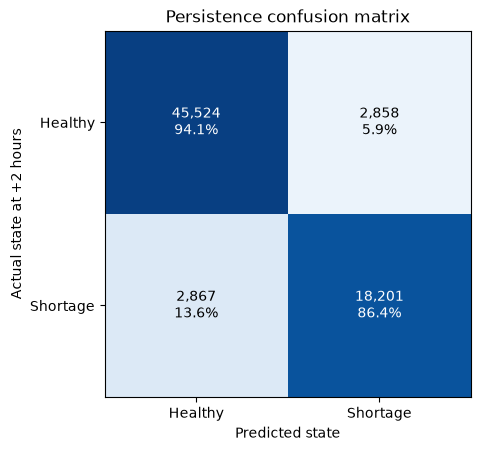

In [25]:
from city_flow.modelling.persistance import evaluation_metrics

ax, metrics = evaluation_metrics(persistence_pairs, confidence=0.95)

print(
    f"TN: {metrics['tn']:,}  FP: {metrics['fp']:,}  "
    f"FN: {metrics['fn']:,}  TP: {metrics['tp']:,}"
)

scores = {
    "accuracy": metrics["accuracy"],
    "precision": metrics["precision"],
    "recall": metrics["recall"],
    "f1": metrics["f1"],
    "new_shortage_rate": metrics["new_shortage_rate"],
}

for name, score in scores.items():
    lower, upper = metrics["confidence_intervals"][name]
    label = name.replace("_", " ").capitalize() if name != "f1" else "F1"
    print(f"{label}: {score:.2%} ({lower:.2%} – {upper:.2%})")

The confidence interval are calculated here by using Wilson score interval. This method allows to compute confidence interval for probability of success calculated from the outcome of a series of success–failure experiments (Bernoulli trials). This method rely on the **assumption that data are distributed according to a binomial distribution**. This implies assuming that data are independent from each other, i.e. there is no temporal or spatial auto-correlation.

## Auto-correlation analysis 

In [20]:
from city_flow.modelling.autocorrelation import (
    error_rate_by_time,
    pearson_autocorrelation,
)

error_rates = error_rate_by_time(persistence_pairs)
acf = pearson_autocorrelation(
    persistence_pairs,
    lags_seconds=[3600 * j for j in range(1, 7 * 25)],
)

In order to estimate the role of autocorrelation in the data, we start by computing the **error rate** over time. This is defined as 
$$e_t = \frac{1}{N_t}\sum_{j \in S_t}|\hat{y}_{j,t+2h}-y_{j,t+2h}| ,$$
where $N_t$ is the number of active stations at time t, and $S_t$ is the set of active stations at time t. (Here active means the set of stations that are not under maintenance or similar limitations.)

We see that the error rate shows a clear **periodicity** over the time of the day, indicating that data are correlated among each other.

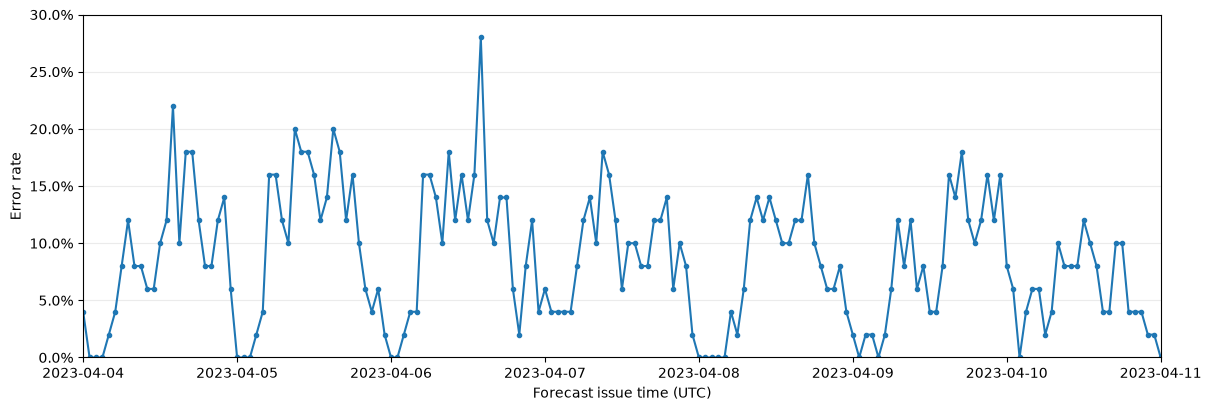

In [21]:
from matplotlib import pyplot as plt
from matplotlib.ticker import PercentFormatter

from city_flow.modelling.autocorrelation import error_rate_by_time

error_rates = error_rate_by_time(persistence_pairs)
issue_times = pd.to_datetime(error_rates["issue_time"], unit="s", utc=True)

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
ax.plot(issue_times, error_rates["error_rate"], marker=".")
ax.set(
    xlabel="Forecast issue time (UTC)",
    xlim=(issue_times[47], issue_times[47 + 7 * 24]),
    ylabel="Error rate",
    ylim=(0, 0.3),
)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(axis="y", alpha=0.25)
plt.show()

The **autocorrelation** can be calculated using Pearson formula, which defines the correlation after a temporal lag $k$ as
$$r(k) = \frac{\sum_{t\in T}(e_t - \bar{e}_{\rm first})(e_{t+k} - \bar{e}_{\rm second})}{\sqrt{\sum_{t\in T}(e_t - \bar{e}_{\rm first})^2}\sqrt{\sum_{t\in T}(e_{t+k} - \bar{e}_{\rm second})^2}} ,$$
where $\bar{e}_{\rm first/second}$ indicates the average error rate of the first/second of the two lagged pairs, and $T$ is the set of times for which both hours have valid error rates. This formula can be used to compute generic correlation between two variables, here we refer to this as **autocorrelation** becuase we are comparing the time series of error rates with itself shifted by a time $k$.

**Interpretation**
- $r(k) > 0$ means hours with above-average error tend to pair with hours that also have above-average error;
- $r(k) < 0$ means above-average error tends to pair with below-average error;
- $r(k) \sim 0$ means little linear association at that lag.

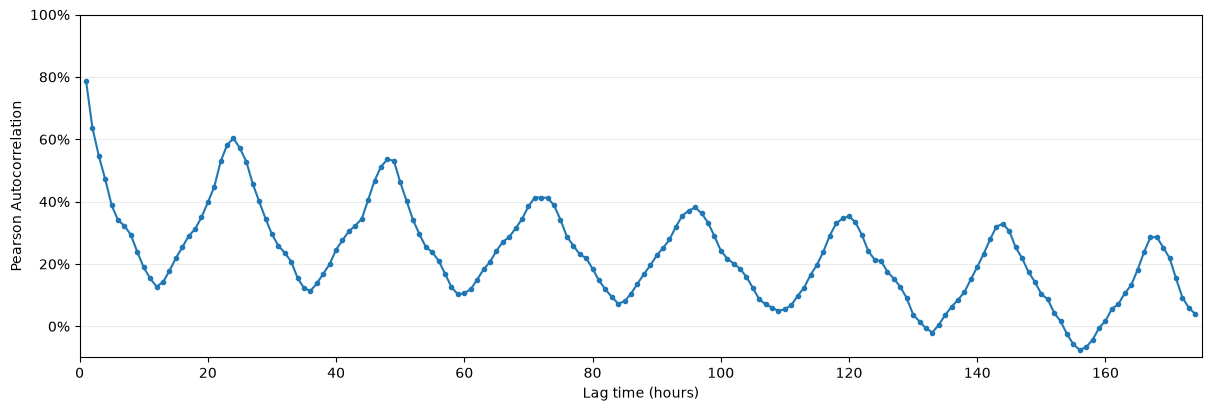

In [28]:
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
ax.plot(acf["lag_seconds"] / 3600, acf["autocorrelation"], marker=".")
ax.set(
    xlabel="Lag time (hours)",
    xlim=(0, 7 * 25),
    ylabel="Pearson Autocorrelation",
    ylim=(-0.1, 1),
)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(axis="y", alpha=0.25)
plt.show()